# Hauptexperiment IV: Weitere Evaluationsmetriken

## Eingaben und Ausgaben

Nach der einmaligen Vorbereitung mit `python 05_analyze.py --prepare` genügt **Run All**.
Die folgende Zelle zeigt Daten, Vorgängertabellen und neue Ausgaben. `DATA_DIR` und
`OUTPUT_DIR` dürfen auf eigene absolute Verzeichnisse zeigen. `TABLES` liest standardmäßig
die vorbereiteten historischen Tabellen; für selbst neu erzeugte Vorgängertabellen
kann hier `OUTPUT_DIR / "tables"` stehen. Eingaben und neue Ausgaben bleiben getrennt.


In [1]:
from pathlib import Path
from faktenretention.paths import PROJECT_ROOT
from faktenretention.text_rules import count_words
from faktenretention.notebook_context import setup_notebook
from faktenretention.io import relative_path, sha

# Hier können eigene absolute Daten- und Ausgabeverzeichnisse stehen.
DATA_DIR = PROJECT_ROOT / "data/prepared"
OUTPUT_DIR = PROJECT_ROOT / "results/notebooks"
# Historische Vorgängertabellen; für eigene Neuberechnungen OUTPUT_DIR / "tables" einsetzen.
TABLES = DATA_DIR / "tables"
setup_notebook(DATA_DIR, OUTPUT_DIR)
OUT = OUTPUT_DIR / "tables/06_weitere_metriken"
FIG = OUTPUT_DIR / "figures/06_weitere_metriken"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
print("Eingaben:", DATA_DIR / "metrics")
print("Vorgängertabellen:", TABLES)
print("Neue Tabellen:", OUT)
print("Neue Grafiken:", FIG)


Eingaben: /home/edgar/Faktenretention_Notebook_Refactor/data/prepared/metrics
Vorgängertabellen: /home/edgar/Faktenretention_Notebook_Refactor/data/prepared/tables
Neue Tabellen: /home/edgar/Faktenretention_Notebook_Refactor/results/notebooks/tables/06_weitere_metriken
Neue Grafiken: /home/edgar/Faktenretention_Notebook_Refactor/results/notebooks/figures/06_weitere_metriken


**Kapitel 4.5 · explorative Ergänzung · aktuell_20260930**

Ordnen ROUGE, BERTScore und SummaC die Verfahren ähnlich wie die beobachtete
QA-Retention? Dieses Notebook untersucht **100 Artikel × sechs Verfahren × vier
Zielstufen = 2.400 Ausgaben**. Die Hauptansicht zeigt die Übereinstimmung der
Methodenrangfolgen innerhalb desselben Artikels. Eine zweite Abbildung vergleicht
SummaC gegen Original und unmittelbaren Stufeneingang.

Alle Modellwerte stammen aus dem aktuellen eingefrorenen Export. ROUGE und der
Zahlenabgleich werden lokal vollständig nachgerechnet; BERTScore und SummaC werden
als gespeicherte Modellwerte verwendet. Es sind keine Modellaufrufe oder Downloads
nötig. Tabellen, Abbildungen, Prüfdaten und Kapiteltext werden beim Ausführen exportiert.

In [2]:
from pathlib import Path
import ast, gzip, hashlib, html, importlib.metadata, json, platform, re
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kendalltau
from rouge_score import rouge_scorer
from IPython.display import display, Markdown, HTML
BASE = DATA_DIR
VERSION="aktuell_20260930"
DATA=DATA_DIR / "qa"
METDATA=DATA_DIR / "metrics"
QADIR=TABLES / "03_qa_retention"
LENDIR=TABLES / "04_laenge_und_adjustierte_retention"
LOSSDIR=TABLES / "05_verlustmuster"
OUT.mkdir(parents=True,exist_ok=True); FIG.mkdir(parents=True,exist_ok=True)
from faktenretention.protocol import METHODS
from faktenretention.protocol import LABELS as NAMES
COLORS=dict(zip(METHODS,["#666666","#0072B2","#E69F00","#009E73","#CC79A7","#D55E00"]))
from faktenretention.protocol import STAGES
KEY=["article_id","method","stage_target_words"]
SECONDARY=["highlight_rougeL_f1","highlight_bertscore_f1","source_summac","stage_input_summac"]
SCORES=["highlight_rouge1_f1","highlight_rouge2_f1"]+SECONDARY
METRICS=["R_obs"]+SCORES+["novel_numeric_rate_vs_article","novel_numeric_rate_vs_stage_input","reference_discordant_rate"]
MET_NAMES={"R_obs":"QA-Retention", "highlight_rouge1_f1":"ROUGE-1 F1", "highlight_rouge2_f1":"ROUGE-2 F1",
 "highlight_rougeL_f1":"ROUGE-L F1", "highlight_bertscore_f1":"BERTScore F1",
 "source_summac":"SummaC: Original", "stage_input_summac":"SummaC: Stufeneingang",
 "novel_numeric_rate_vs_article":"Neue Zahlen: Original", "novel_numeric_rate_vs_stage_input":"Neue Zahlen: Stufeneingang",
 "reference_discordant_rate":"Referenzabweichende QA"}
SEED,B=32,10_000
pd.set_option("display.max_rows",26); pd.set_option("display.max_columns",12)
plt.rcParams.update({"font.size":11,"figure.dpi":110,"savefig.dpi":220,
                     "axes.spines.top":False,"axes.spines.right":False})
def read(p): return pd.read_csv(p,keep_default_na=False,low_memory=False)
def text_sha(s): return hashlib.sha256(s.encode()).hexdigest()
def export(frame,name): frame.to_csv(OUT/f"{name}.csv",index=False)
def fmt(x,d=2): return f"{x:.{d}f}".replace(".",",")
def boolean(s): return s.astype(str).str.lower().eq("true")
def savefig(fig,name):
    for ext in ["png","svg","pdf"]: fig.savefig(FIG/f"{name}.{ext}",bbox_inches="tight")
    plt.show(); plt.close(fig)
software={p:importlib.metadata.version(p) for p in ["numpy","pandas","scipy","matplotlib","rouge-score","nltk","nbformat","nbclient","nbconvert","ipykernel","ipython"]}


## Kurzbefund

Die folgende Übersicht wird aus den ausgeführten Ergebnissen erzeugt. Methodik und
vollständige Prüfdaten stehen darunter; die kurze Ergebnisfassung am Ende enthält
konkrete Werte für den Kapiteltext.

In [3]:
# Die Übersicht wird nach der Berechnung in diese früh platzierte Anzeige geschrieben.
summary_display=display(Markdown("Auswertung wird berechnet …"),display_id=True)


Auswertung wird berechnet …

## 1. Kontext, Kennzahlen und Annahmen

Keine neue Hypothese: Die Vergleiche und die Auswahl einzelner Widersprüche sind
**explorativ**. Alle Gruppenwerte sind gleichgewichtete Mittel von Artikelwerten.
Bei QA ist der Artikelwert `R_obs = n_retained / n_valid`; technische Fehlwerte
bleiben aus dem gültigen QA-Nenner ausgeschlossen. Ein gepoolter Faktenanteil
ist ein anderes Schätzmaß und wird nur als ergänzende Nennerkontrolle exportiert.

| Kennzahl | Referenz und tatsächlich verwendete Variante |
|---|---|
| ROUGE-1/2/L | F1 je Ausgabe gegen menschliche CNN/DailyMail-Highlights; `use_stemmer=True`; Skala 0–1; ROUGE-L, nicht ROUGE-Lsum. |
| BERTScore | F1 gegen dieselben Highlights; distilroberta-base, Revision `fb53ab8802853c8e4fbdbcd0529f21fc6f459b2b`; Englisch, Layer 6, `rescale_with_baseline=False`; keine IDF-Option gesetzt. |
| SummaC Original | SummaCConv, `vitc`, Satzgranularität, Perzentil-Bins, trainierter Standardkopf; vollständiger Originalartikel als Referenz. |
| SummaC Stufeneingang | Identischer Scorer; Original bei 500, danach unmittelbar vorherige Zusammenfassung desselben Artikels und Verfahrens. |
| Neue Zahlen | Anteil der Ausgaben mit mindestens einer neu normalisierten Ziffernfolge; getrennt gegen Original und Stufeneingang. |
| Referenzabweichende QA | `n_reference_discordant / n_valid`; getrennt von Lost und technischen QA-Fehlwerten. |

Die Modellkonfiguration wird aus Manifest und eingefrorenem Berechnungscode
rekonstruiert. SummaC verwendet das gepinnte NLI-Modell
`tals/albert-xlarge-vitaminc-mnli`, Revision `3082ba54344bd9ddada2be1c5e9b4131721d2a5d`,
und den Kopf mit SHA-256 `cd880581f59bd47b8968c7f48d754cd617dfe9b256d8d76fdcbc0fa4a3b3c6fe`.
Die Bibliotheksversionsliste des Ursprungslaufs ist eine Anforderungsdatei, kein
vollständiger Freeze seiner Laufzeit. Die Versionen der aktuellen Auswertung werden separat gespeichert.

### Wesentliche Annahmen und Grenzen

- Die Highlights sind keine Liste der 20 Ausgangsfakten. Ihre Länge wird geprüft;
  Referenzähnlichkeit und QA-Faktenabdeckung messen unterschiedliche Aspekte.
- Neue Zahlen: Währungszeichen, Prozentzeichen, Kommas und Leerzeichen werden
  entfernt. Zahlwörter, Einheiten, Kontext und Umrechnungen werden nicht semantisch
  abgeglichen. Das ist **keine Halluzinationsrate**.
- Die zwei leeren Ausgaben behalten die ausdrücklich gespeicherte Nullwertregel
  für Scores. Diese Regelwerte werden ausgewiesen; fehlende Werte werden nicht aufgefüllt.
- Bei einem **leeren Stufeneingang** ist dessen Vergleich inhaltlich nicht auswertbar:
  gespeicherter lokaler SummaC-Score und lokaler Zahlenindikator bleiben im Rohexport,
  werden aber in der Analyse fehlend gesetzt. Originalbezüge bleiben auswertbar.
- Punktweise 95-%-Perzentilintervalle: 10.000 Artikelbootstrap-Ziehungen, Seed 32.
  Ein Artikel bringt alle Verfahren und Stufen mit. Keine Korrektur für Mehrfachvergleiche,
  keine Unsicherheit der automatischen Modelle, kein Validierungs- oder Kausalnachweis.

## 2. Quellen und Abgleich mit 4.2–4.4

Die aktuelle zusammengeführte Summary-Datei stimmt bytegenau mit dem dekomprimierten
Snapshot der bisherigen Kapitel überein. Die Metrikherkunft ist durch Ablaufprotokoll,
Manifest und Nachberechnung dokumentiert. Im Ursprungs-Metrikexport liegen keine
separaten Summary-Hashes je Modellscore vor; diese Grenze wird nicht als neuer
Modelllauf ausgegeben. Zuordnung ausschließlich über Artikel-ID × vollständigen
Verfahrensnamen × Zielstufe.

In [4]:
from faktenretention.text_rules import count_words
source_manifest=json.loads((DATA/"source_manifest.json").read_text())
metric_manifest=json.loads((METDATA/"source_manifest.json").read_text())
assert metric_manifest["version"]==VERSION
assert sha(DATA/"source_manifest.json")==metric_manifest["qa_source_manifest_sha256"]
source_hashes=[]
for root,entries in [(DATA,source_manifest["files"]),(METDATA,metric_manifest["files"])]:
    for e in entries:
        if root==DATA and not e["file"].startswith((VERSION+"/","shared/","code/")): continue
        p=root/e["file"]; assert sha(p)==e["sha256"],p
        if p.suffix==".gz": assert hashlib.sha256(gzip.decompress(p.read_bytes())).hexdigest()==e["original_sha256"],p
        source_hashes.append(dict(file=relative_path(p, BASE),sha256=sha(p),role="frozen_input"))
assert hashlib.sha256(gzip.decompress((DATA/VERSION/"summaries.csv.gz").read_bytes())).hexdigest()==metric_manifest["summary_original_sha256"]
for folder in [QADIR,LENDIR,LOSSDIR]:
    previous=json.loads((folder/"execution_manifest.json").read_text())
    assert previous["version"]==VERSION
    if "source_manifest_sha256" in previous: assert previous["source_manifest_sha256"]==sha(DATA/"source_manifest.json")
    for e in previous.get("source_hashes",[]): assert sha(BASE/e["file"])==e["sha256"]
    source_hashes.append(dict(file=relative_path((folder/"execution_manifest.json"), BASE),sha256=sha(folder/"execution_manifest.json"),role="previous_chapter"))
merge=json.loads((DATA/VERSION/"provenienz/result_merge_manifest.json").read_text())
assert merge["retained_historical_rows"]==400 and merge["replaced_plain_rows"]==merge["replaced_few_shot_rows"]==100
assert merge["historical_plain_or_few_shot_rows_in_new_table"]==0
summaries=read(DATA/VERSION/"summaries.csv.gz")
articles=read(DATA/"shared/test_articles.csv.gz")
raw_scores=read(METDATA/VERSION/"metrics_detailed.csv")
archived_groups=read(METDATA/VERSION/"metrics_by_method_stage.csv")
qa=read(QADIR/"retention_artikelebene.csv")
lengths=read(LENDIR/"artikelwerte_laenge_retention.csv")
generation=read(QADIR/"generation_status_und_rekursive_eingaben.csv")
for p in [QADIR/"retention_artikelebene.csv",LENDIR/"artikelwerte_laenge_retention.csv",QADIR/"generation_status_und_rekursive_eingaben.csv"]:
    source_hashes.append(dict(file=relative_path(p, BASE),sha256=sha(p),role="keyed_join"))
IDS=sorted(articles.article_id.tolist())
assert len(IDS)==100 and articles.article_id.is_unique and len(summaries)==600
expected={(a,m,t) for a in IDS for m in METHODS for t in STAGES}
for f in [raw_scores,qa,lengths,generation]:
    assert len(f)==2400 and not f.duplicated(KEY).any()
    assert set(f[KEY].itertuples(index=False,name=None))==expected
assert not summaries.duplicated(["article_id","method"]).any()
phase={m:"plain_fewshot_rerun_20260930" if m in ["plain","few_shot_cot"] else "final_100_frozen_temperature_0" for m in METHODS}
assert summaries.collection_phase.eq(summaries.method.map(phase)).all()
original=summaries.merge(articles[["article_id","article","highlights","dataset_index"]],on="article_id",validate="many_to_one",suffixes=("","_canonical"))
for c in ["article","highlights","dataset_index"]: assert original[c].eq(original[c+"_canonical"]).all()
records=[]
for row in summaries.to_dict("records"):
    for i,t in enumerate(STAGES):
        summary=str(row[f"summary_{t}"]).strip()
        stage_input=str(row["article"] if i==0 else row[f"summary_{STAGES[i-1]}"])
        records.append(dict(article_id=row["article_id"],method=row["method"],stage_target_words=t,
                            dataset_index=row["dataset_index"],summary=summary,article=row["article"],highlights=row["highlights"],
                            stage_input=stage_input,input_reference="original" if i==0 else f"summary_{STAGES[i-1]}",
                            summary_sha256=text_sha(summary),input_sha256=text_sha(stage_input),
                            highlight_sha256=text_sha(row["highlights"])))
texts=pd.DataFrame(records)
checks=texts.merge(generation[KEY+["input_sha256","output_sha256","input_reference","empty_input","empty_output"]],on=KEY,validate="one_to_one",suffixes=("","_generation"))
assert checks.input_sha256.eq(checks.input_sha256_generation).all()
assert checks.summary_sha256.eq(checks.output_sha256).all()
assert checks.input_reference.eq(checks.input_reference_generation).all()
assert checks.stage_input.str.strip().eq("").eq(boolean(checks.empty_input)).all()
assert checks.summary.eq("").eq(boolean(checks.empty_output)).all()
joined=raw_scores.merge(texts,on=KEY,validate="one_to_one",suffixes=("","_text"))
assert joined.dataset_index.eq(joined.dataset_index_text).all()
joined=joined.drop(columns="dataset_index_text")
joined=joined.merge(qa[KEY+["n_total","n_valid","n_missing","n_retained","n_lost","n_reference_discordant","retention_observed"]],on=KEY,validate="one_to_one")
joined=joined.merge(lengths[KEY+["summary_sha256","W","U","O","D","R_obs","R_adj","chain_failure"]],on=KEY,validate="one_to_one",suffixes=("","_43"))
assert joined.summary_sha256.eq(joined.summary_sha256_43).all()
assert np.allclose(joined.R_obs,joined.retention_observed,atol=1e-14)
assert np.allclose(joined.R_obs,joined.n_retained/joined.n_valid,atol=1e-14)
assert joined.n_missing.sum()==196 and joined.n_total.eq(20).all()
joined["reference_discordant_rate"]=joined.n_reference_discordant/joined.n_valid
joined["W_recomputed"]=joined.summary.map(count_words)
assert joined.W_recomputed.eq(joined.W).all() and joined.W.eq(joined.stage_actual_words).all()
assert np.allclose(joined.D,joined.word_window_violation_rate,atol=1e-14)
assert joined.U.eq(joined.accepted_min_words).all() and joined.O.eq(joined.accepted_max_words).all()
joined["empty_input"]=joined.stage_input.str.strip().eq("")
assert joined.empty_output.eq(joined.summary.eq("").astype(int)).all()
assert joined.empty_output.sum()==2 and joined.empty_input.sum()==1
assert joined.loc[joined.empty_output.eq(1),SCORES].eq(0).all().all()
assert joined.loc[joined.stage_target_words.eq(500),"source_summac"].eq(joined.loc[joined.stage_target_words.eq(500),"stage_input_summac"]).all()
export(pd.DataFrame(source_hashes),"quellen_sha256")
export(joined,"artikelwerte_roh_mit_referenzen")
print("Geprüft: 2.400 eindeutige Schlüssel; identische Summary-/Input-Hashes; 196 technische QA-Fehlwerte; 2 leere Ausgaben; 1 leerer Stufeneingang; 600 identische SummaC-Bezüge bei 500.")


Geprüft: 2.400 eindeutige Schlüssel; identische Summary-/Input-Hashes; 196 technische QA-Fehlwerte; 2 leere Ausgaben; 1 leerer Stufeneingang; 600 identische SummaC-Bezüge bei 500.


### 2.1 Vollständige Nachberechnung von ROUGE und neuen Zahlen

Der Zahlenextraktor wird direkt aus dem eingefrorenen Ursprungscode geladen (nur
die einzelne Funktion, keine Modellimporte). Listen mit leerem String bedeuten
**keinen neuen Wert** und sind keine technischen Fehlwerte. Für semantische Modelle
wird der gespeicherte Scorebereich geprüft, ohne eine neue Modellbewertung zu behaupten.

In [5]:
from faktenretention.metrics import numeric_tokens
recalculated=raw_scores[KEY+["highlight_rouge1_f1","highlight_rouge2_f1","highlight_rougeL_f1"]].copy()
for ref,field in [("article","article"),("stage_input","stage_input")]:
    computed=["|".join(sorted(numeric_tokens(s)-numeric_tokens(r))) for s,r in zip(joined.summary,joined[ref])]
    assert joined[f"novel_numeric_tokens_vs_{field}"].eq(computed).all()
    assert joined[f"novel_numeric_rate_vs_{field}"].eq(pd.Series(computed).ne("").astype(int)).all()
for c in SCORES+["novel_numeric_rate_vs_article","novel_numeric_rate_vs_stage_input"]:
    assert pd.to_numeric(joined[c],errors="coerce").notna().all(),c
    assert joined[c].between(0,1).all(),c

# Gespeicherte Gruppenmittel vor analytischer Ausnahmeregel nachrechnen.
reconciliation=[]
for r in archived_groups.itertuples(index=False):
    x=raw_scores.loc[raw_scores.method.eq(r.method)&raw_scores.stage_target_words.eq(r.stage_target_words),r.metric].astype(float)
    reconciliation.append(dict(method=r.method,stage_target_words=r.stage_target_words,metric=r.metric,n_recomputed=len(x),n_archived=r.n_articles,
                               mean_recomputed=x.mean(),mean_archived=r.mean,abs_error=abs(x.mean()-r.mean)))
reconciliation=pd.DataFrame(reconciliation)
assert len(reconciliation)==384 and reconciliation.n_recomputed.eq(reconciliation.n_archived).all()
assert reconciliation.abs_error.max()<1e-12
export(reconciliation,"abgleich_archivierte_384_gruppenwerte")
analysis=joined.copy()
for c in ["stage_input_summac","novel_numeric_rate_vs_stage_input"]:
    analysis[c+"_stored"]=analysis[c]
    analysis.loc[analysis.empty_input,c]=np.nan
analysis["local_reference_unusable_reason"]=np.where(analysis.empty_input,"empty_immediate_input","")
analysis["score_origin"]=np.where(analysis.empty_output.eq(1),"empty_output_zero_rule","frozen_output_score")
export(analysis,"artikelwerte_metriken_2400")
range_audit=pd.DataFrame([dict(metric=c,n_rows=len(analysis),n_valid=analysis[c].notna().sum(),n_missing=analysis[c].isna().sum(),
                             min=analysis[c].min(),max=analysis[c].max(),missing_reason="empty_immediate_input" if analysis[c].isna().any() else "none",
                             n_zero_rule=int(analysis.empty_output.sum()) if c in SCORES else 0) for c in METRICS])
export(range_audit,"wertebereiche_und_fehlwerte")
display(range_audit.rename(columns={"metric":"Kennzahl","n_valid":"Gültige Ausgaben","n_missing":"Fehlend","missing_reason":"Grund"}))
print(f"384 archivierte Gruppenmittel reproduziert; maximale Abweichung {reconciliation.abs_error.max():.2g}. ROUGE-Einzelwerte wiederverwendet; 4.800 Zahlenindikatoren nachgerechnet.")


,Kennzahl,n_rows,Gültige Ausgaben,Fehlend,min,max,Grund,n_zero_rule
0,R_obs,2400,2400,0,0.0,1.000000,none,0
1,highlight_rouge1_f1,2400,2400,0,0.0,0.645669,none,2
2,highlight_rouge2_f1,2400,2400,0,0.0,0.480000,none,2
3,highlight_rougeL_f1,2400,2400,0,0.0,0.490066,none,2
4,highlight_bertscore_f1,2400,2400,0,0.0,0.952501,none,2
5,source_summac,2400,2400,0,0.0,0.503770,none,2
6,stage_input_summac,2400,2399,1,0.0,0.434003,empty_immediate_input,2
7,novel_numeric_rate_vs_article,2400,2400,0,0.0,1.000000,none,0
8,novel_numeric_rate_vs_stage_input,2400,2399,1,0.0,1.000000,empty_immediate_input,0
9,reference_discordant_rate,2400,2400,0,0.0,0.600000,none,0


384 archivierte Gruppenmittel reproduziert; maximale Abweichung 1.7e-16. ROUGE-Einzelwerte wiederverwendet; 4.800 Zahlenindikatoren nachgerechnet.


## 3. Artikelbootstrap und 24-Gruppen-Ergebnisse

Für jede Kennzahl werden Mittelwert, Standardabweichung, gültiges n und Intervall
exportiert. Derselbe Satz gezogener Artikel wird über Verfahren und Stufen verwendet.
Fehlende Kennzahlen bleiben fehlend: im Bootstrap werden gültige Artikel innerhalb
jeder Ziehung verwendet. Bei gepaarten Differenzen zählt nur der gemeinsame gültige
Artikel. Ausgaben mit gespeicherter Nullwertregel bleiben gesondert erkennbar.

In [6]:
rng=np.random.default_rng(SEED)
indices=rng.integers(0,len(IDS),size=(B,len(IDS)))
weights=np.zeros((B,len(IDS)),dtype=np.int16)
np.add.at(weights,(np.repeat(np.arange(B),len(IDS)),indices.ravel()),1)
def estimates(values,ids=IDS,draw_weights=weights):
    a=pd.Series(values,index=ids,dtype=float).reindex(ids).to_numpy()
    valid=np.isfinite(a)
    if not valid.any(): return np.full(len(draw_weights),np.nan)
    denom=draw_weights@valid.astype(float)
    return np.divide(draw_weights@np.nan_to_num(a),denom,out=np.full(len(draw_weights),np.nan),where=denom>0)
def describe(values,ids=IDS,draw_weights=weights):
    a=pd.Series(values,index=ids,dtype=float).to_numpy()
    boot=estimates(a,ids,draw_weights)
    low,high=np.nanquantile(boot,[.025,.975]) if np.isfinite(boot).any() else (np.nan,np.nan)
    valid=a[np.isfinite(a)]
    return dict(mean=float(valid.mean()) if len(valid) else np.nan,
                sd=float(valid.std(ddof=1)) if len(valid)>1 else np.nan,
                n_valid=len(valid),n_missing=len(a)-len(valid),ci_low=low,ci_high=high),boot
group_rows=[]; group_draws={}
for m in METHODS:
    for t in STAGES:
        g=analysis[analysis.method.eq(m)&analysis.stage_target_words.eq(t)].set_index("article_id").reindex(IDS)
        for metric in METRICS:
            stats,boot=describe(g[metric].to_numpy())
            group_rows.append(dict(method=m,method_name=NAMES[m],stage_target_words=t,metric=metric,**stats,
                                   n_qa_valid=int(g.n_valid.sum()),n_qa_missing=int(g.n_missing.sum()),
                                   n_empty_outputs=int(g.empty_output.sum()),n_empty_inputs=int(g.empty_input.sum()),
                                   missing_reason="empty_immediate_input" if stats["n_missing"] else "none"))
            group_draws[f"{m}__{t}__{metric}"]=boot
groups=pd.DataFrame(group_rows)
export(groups,"mittelwerte_24_gruppen_alle_metriken_95ci")
pass  # Große Bootstrap-Zwischendatei wird nicht benötigt.
wide=groups.pivot(index=["method","stage_target_words"],columns="metric",values="mean").reset_index()
export(wide,"mittelwerte_24_gruppen_breit")
diagnostic=[]
for (m,t),g in analysis.groupby(["method","stage_target_words"]):
    diagnostic.append(dict(method=m,method_name=NAMES[m],stage_target_words=t,n_articles=len(g),
        n_qa_valid=int(g.n_valid.sum()),n_qa_missing=int(g.n_missing.sum()),n_qa_lost=int(g.n_lost.sum()),
        n_qa_discordant=int(g.n_reference_discordant.sum()),qa_mean_article=g.R_obs.mean(),
        qa_pooled=g.n_retained.sum()/g.n_valid.sum(),discordant_mean_article=g.reference_discordant_rate.mean(),
        discordant_pooled=g.n_reference_discordant.sum()/g.n_valid.sum(),
        n_numeric_original=int(g.novel_numeric_rate_vs_article.notna().sum()),
        n_numeric_local=int(g.novel_numeric_rate_vs_stage_input.notna().sum()),
        numeric_original_rate=g.novel_numeric_rate_vs_article.mean(),numeric_local_rate=g.novel_numeric_rate_vs_stage_input.mean(),
        n_empty_outputs=int(g.empty_output.sum()),n_empty_inputs=int(g.empty_input.sum()),
        actual_words_mean=g.W.mean(),length_deviation_mean=g.D.mean(),n_over_window=int(g.W.gt(g.O).sum())))
diagnostics=pd.DataFrame(diagnostic)
export(diagnostics,"diagnostik_24_gruppen_qa_zahlen_laenge")
reference_lengths=articles.assign(article_words=articles.article.map(count_words),
                                  highlight_words=articles.highlights.map(count_words))
export(reference_lengths[["article_id","dataset_index","article_words","highlight_words"]],"referenzlaengen")
display(Markdown(f"Die Highlights haben im Median **{fmt(reference_lengths.highlight_words.median(),0)} Wörter** (Spanne {reference_lengths.highlight_words.min()}–{reference_lengths.highlight_words.max()}). Gültiges n: 100 je Gruppe; nur die lokalen Bezüge von Zero-Shot-CoT bei 75 Wörtern verwenden n=99. Vollständige Zahlen stehen im CSV-Export."))


Die Highlights haben im Median **50 Wörter** (Spanne 21–147). Gültiges n: 100 je Gruppe; nur die lokalen Bezüge von Zero-Shot-CoT bei 75 Wörtern verwenden n=99. Vollständige Zahlen stehen im CSV-Export.

## 4. Übereinstimmung der Methodenordnung innerhalb eines Artikels

Kendall-τ-b wird je Artikel × Stufe × Sekundärmetrik zwischen QA und den sechs
Methodenscores berechnet. Gleichstände werden durch τ-b berücksichtigt. Für die
Hauptanalyse werden **alle sechs Methoden** verlangt; unvollständige oder konstante
Rangvektoren bleiben undefiniert. Anzahl verfügbarer Methoden, Gleichstandspaare und
Grund jeder undefinierten Korrelation werden exportiert. Wertebereich −1 bis +1.

Vor der Darstellung festgelegte Nutzbarkeitsregel: mindestens 80 gültige Artikel
in jeder Metrik-Stufen-Zelle; sonst wird eine Rangmatrix der Gruppenmittel gezeigt.
Das ist eine Darstellungsentscheidung, kein Signifikanzkriterium.

In [7]:
def article_correlations(frame,ids):
    rows=[]
    for a in ids:
        for t in STAGES:
            g=frame[frame.article_id.eq(a)&frame.stage_target_words.eq(t)].set_index("method").reindex(METHODS)
            for metric in SECONDARY:
                x=g.R_obs.to_numpy(float); y=g[metric].to_numpy(float)
                valid=np.isfinite(x)&np.isfinite(y)
                qt=sum(x[i]==x[j] for i,j in combinations(np.where(valid)[0],2))
                mt=sum(y[i]==y[j] for i,j in combinations(np.where(valid)[0],2))
                if valid.sum()<6: tau=np.nan; reason="incomplete_six_method_panel"
                elif len(np.unique(x))==1: tau=np.nan; reason="all_qa_tied"
                elif len(np.unique(y))==1: tau=np.nan; reason="all_secondary_tied"
                else: tau=float(kendalltau(x,y,variant="b").statistic); reason="" if np.isfinite(tau) else "undefined_other"
                rows.append(dict(article_id=a,stage_target_words=t,metric=metric,tau_b=tau,n_methods_valid=int(valid.sum()),
                                 qa_tie_pairs=qt,secondary_tie_pairs=mt,undefined_reason=reason))
    return pd.DataFrame(rows)
article_tau=article_correlations(analysis,IDS)
export(article_tau,"kendall_tau_b_artikelebene_1600")
tau_rows=[]; tau_draws={}
for t in STAGES:
    for metric in SECONDARY:
        g=article_tau[article_tau.stage_target_words.eq(t)&article_tau.metric.eq(metric)].set_index("article_id").reindex(IDS)
        stats,boot=describe(g.tau_b.to_numpy())
        tau_rows.append(dict(stage_target_words=t,metric=metric,**stats,n_articles_with_qa_ties=int(g.qa_tie_pairs.gt(0).sum()),
                             undefined_reasons=json.dumps(g.loc[g.tau_b.isna(),"undefined_reason"].value_counts().to_dict())))
        tau_draws[f"{t}__{metric}"]=boot
tau_summary=pd.DataFrame(tau_rows)
export(tau_summary,"kendall_tau_b_mittelwerte_95ci")
export(tau_summary.assign(metric_name=tau_summary.metric.map(MET_NAMES)),"abbildung_4_5_1_punktwerte")
pass  # Große Bootstrap-Zwischendatei wird nicht benötigt.
use_tau=tau_summary.n_valid.ge(80).all()
display(tau_summary[["stage_target_words","metric","mean","ci_low","ci_high","n_valid","n_missing"]].round(3))


,stage_target_words,metric,mean,ci_low,ci_high,n_valid,n_missing
0,500,highlight_rougeL_f1,-0.346,-0.410,-0.278,100,0
1,500,highlight_bertscore_f1,-0.143,-0.217,-0.070,100,0
2,500,source_summac,0.067,-0.004,0.139,100,0
3,500,stage_input_summac,0.067,-0.004,0.139,100,0
4,300,highlight_rougeL_f1,-0.327,-0.383,-0.269,100,0
5,300,highlight_bertscore_f1,-0.315,-0.376,-0.254,100,0
6,300,source_summac,0.004,-0.072,0.080,100,0
7,300,stage_input_summac,-0.053,-0.120,0.014,100,0
8,150,highlight_rougeL_f1,-0.335,-0.397,-0.272,100,0
9,150,highlight_bertscore_f1,-0.544,-0.593,-0.494,100,0


### Abbildung 4.5-1: Übereinstimmung mit QA

Jeder Punkt ist ein gleichgewichteter Mittelwert artikelweiser τ-b-Werte. Horizontale
Intervalle sind punktweise 95-%-Artikelbootstrap-Intervalle. Die vier Panels verwenden
dieselbe Skala und zeigen die Zahl der jeweils gültigen Artikel direkt am Punkt.

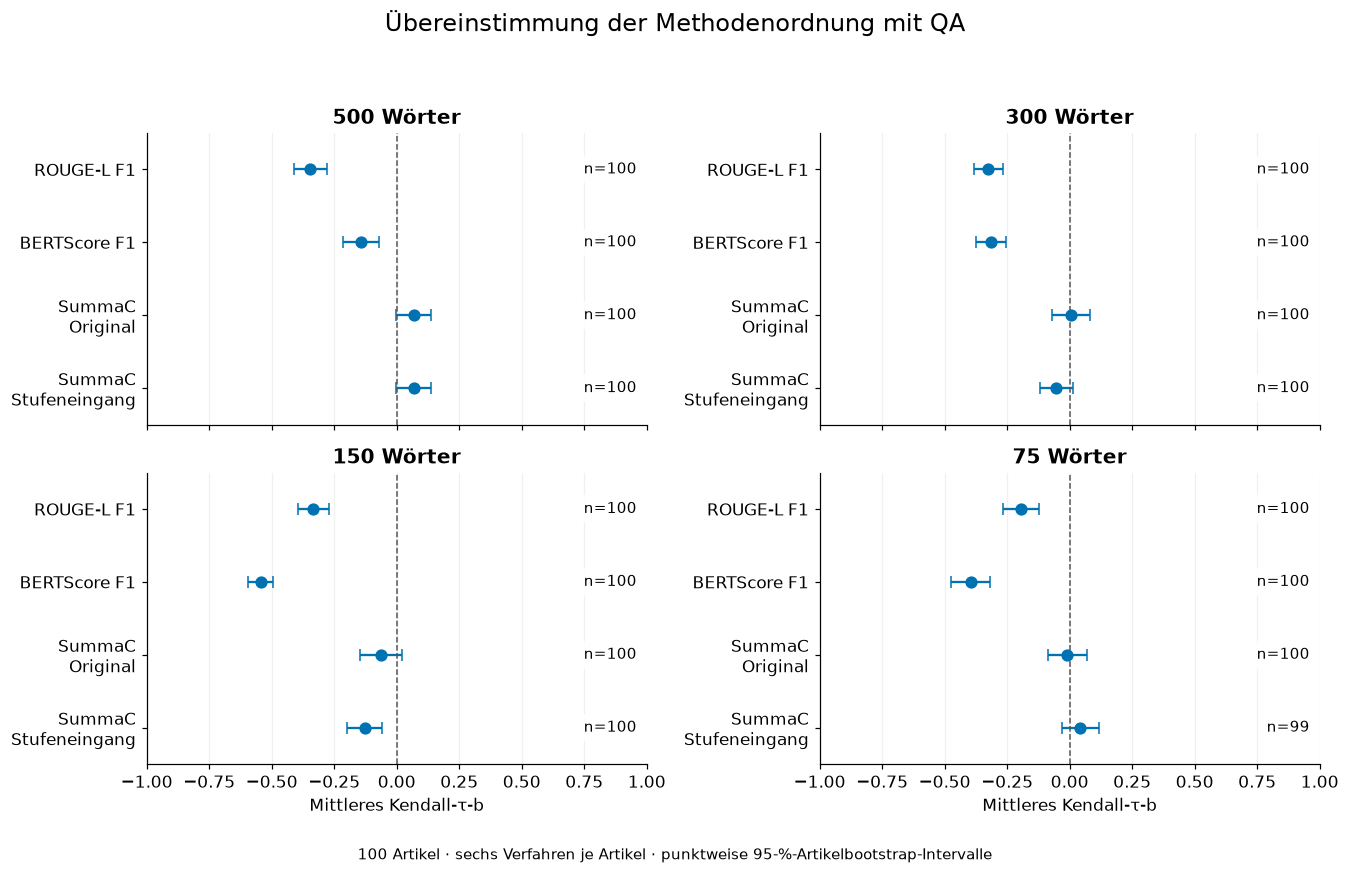

**Darstellungsentscheidung:** 99–100 gültige Artikel je Zelle; deshalb artikelweises Kendall-τ-b. 12 von 16 mittleren Rangübereinstimmungen sind negativ. Eine ähnliche oder gegensätzliche Ordnung ist kein Nachweis der Gültigkeit einer Metrik.

In [8]:
fig,axes=plt.subplots(2,2,figsize=(12.4,8),sharex=True,sharey=True)
if use_tau:
    for ax,t in zip(axes.flat,STAGES):
        g=tau_summary[tau_summary.stage_target_words.eq(t)].set_index("metric").reindex(SECONDARY)
        for i,(metric,r) in enumerate(g.iterrows()):
            ax.errorbar(r["mean"],i,xerr=[[r["mean"]-r.ci_low],[r.ci_high-r["mean"]]],fmt="o",color="#0072B2",capsize=4,ms=7)
            ax.text(.96,i,f"n={int(r.n_valid)}",ha="right",va="center",fontsize=10,
                    bbox=dict(facecolor="white",edgecolor="none",alpha=.9))
        ax.axvline(0,color="#555555",ls="--",lw=1)
        ax.set_yticks(range(4),[MET_NAMES[m].replace(": ","\n") for m in SECONDARY])
        ax.set_xlim(-1,1); ax.set_ylim(3.5,-.5)
        ax.set_title(f"{t} Wörter",fontweight="bold"); ax.grid(axis="x",alpha=.18)
        ax.tick_params(labelleft=True)
    for ax in axes[1]: ax.set_xlabel("Mittleres Kendall-τ-b")
    fig.suptitle("Übereinstimmung der Methodenordnung mit QA",fontsize=16,y=.98)
    fig.text(.5,.015,"100 Artikel · sechs Verfahren je Artikel · punktweise 95-%-Artikelbootstrap-Intervalle",ha="center",fontsize=10)
else:
    for ax,t in zip(axes.flat,STAGES):
        matrix=groups[(groups.stage_target_words.eq(t))&groups.metric.isin(["R_obs"]+SECONDARY)].pivot(index="method",columns="metric",values="mean").reindex(index=METHODS,columns=["R_obs"]+SECONDARY).rank(ascending=False,method="average")
        ax.imshow(matrix,vmin=1,vmax=6,cmap="YlGnBu")
        for i in range(6):
            for j in range(5): ax.text(j,i,fmt(matrix.iloc[i,j],1),ha="center",va="center",color="white" if matrix.iloc[i,j]>=4 else "black")
        ax.set_yticks(range(6),[NAMES[m] for m in METHODS]); ax.set_xticks(range(5),["QA","ROUGE-L","BERTScore","SummaC\nOriginal","SummaC\nEingang"],rotation=35,ha="right"); ax.set_title(f"{t} Wörter")
    fig.suptitle("Methodenränge der Gruppenmittel (1 = höchster Wert)",fontsize=15)
fig.tight_layout(rect=[0,.045,1,.94])
savefig(fig,"abbildung_4_5_1_methodenordnung_qa")
negative=int(tau_summary["mean"].lt(0).sum())
min_valid=int(tau_summary.n_valid.min())
display(Markdown(f"**Darstellungsentscheidung:** {min_valid}–{int(tau_summary.n_valid.max())} gültige Artikel je Zelle; deshalb {'artikelweises Kendall-τ-b' if use_tau else 'Rangmatrix als Ersatz'}. {negative} von 16 mittleren Rangübereinstimmungen sind negativ. Eine ähnliche oder gegensätzliche Ordnung ist kein Nachweis der Gültigkeit einer Metrik."))


## 5. Methodenränge und systematische Suche nach Widersprüchen

Alle 15 Methodenpaare werden in jeder Stufe gegen vier Haupt-Sekundärmetriken
geprüft: **240 Paar-Metrik-Stufen-Vergleiche**. Ein Widerspruch ist ein entgegengesetztes
Vorzeichen der mittleren QA- und Sekundärmetrik-Differenz auf denselben gültigen
Artikeln. Intervalle dienen der Einordnung und begründen keine vorab geplante Hypothese.
ROUGE-1/2 werden zusätzlich vollständig exportiert, ohne die Beispielauswahl zu erweitern.

Auswahlregel für höchstens zwei Beispiele: aus Vorzeichenwidersprüchen, deren beide
punktweisen Intervalle null ausschließen, je ROUGE-L und BERTScore zuerst der größte
QA-Abstand; ein bereits gewähltes Paar mit gleicher Stufe wird übersprungen. Wenn
keines existiert, wird für die betreffende Metrik kein Beispiel ausgewählt.
Die Auswahl ist ausdrücklich nachträglich und explorativ. Wortzahlen und Fensterabweichung
werden für dieselben Paare mitberichtet; die Differenzen sind nicht längenbereinigt.

In [9]:
rank_rows=[]
for t in STAGES:
    for metric in ["R_obs"]+SCORES:
        g=groups[groups.stage_target_words.eq(t)&groups.metric.eq(metric)].copy()
        g["rank"]=g["mean"].rank(ascending=False,method="average")
        g=g.sort_values(["rank","method"])
        g["gap_to_top"]=g["mean"].max()-g["mean"]
        g["gap_from_previous"]=g["mean"].shift(1)-g["mean"]
        rank_rows.append(g)
ranks=pd.concat(rank_rows,ignore_index=True)
export(ranks,"methodenraenge_und_abstaende")
def paired_contrasts(frame,ids,draw_weights):
    rows=[]; draws={}
    for t in STAGES:
        panel={m:frame[frame.method.eq(m)&frame.stage_target_words.eq(t)].set_index("article_id").reindex(ids) for m in METHODS}
        for left,right in combinations(METHODS,2):
            for metric in SECONDARY+["highlight_rouge1_f1","highlight_rouge2_f1"]:
                a,b=panel[left],panel[right]
                valid=a.R_obs.notna()&b.R_obs.notna()&a[metric].notna()&b[metric].notna()
                qa_diff=(a.R_obs-b.R_obs).where(valid)
                sec_diff=(a[metric]-b[metric]).where(valid)
                q,qboot=describe(qa_diff.to_numpy(),ids,draw_weights)
                s,sboot=describe(sec_diff.to_numpy(),ids,draw_weights)
                conflict=q["mean"]*s["mean"]<0
                both_exclude=(q["ci_low"]*q["ci_high"]>0)&(s["ci_low"]*s["ci_high"]>0)
                row=dict(stage_target_words=t,method_a=left,method_b=right,metric=metric,n_pairs=q["n_valid"],
                         qa_diff=q["mean"],qa_ci_low=q["ci_low"],qa_ci_high=q["ci_high"],
                         metric_diff=s["mean"],metric_ci_low=s["ci_low"],metric_ci_high=s["ci_high"],
                         sign_disagreement=conflict,both_pointwise_intervals_exclude_zero=bool(both_exclude),
                         qa_winner=left if q["mean"]>0 else right,metric_winner=left if s["mean"]>0 else right,
                         actual_words_a=a.loc[valid,"W"].mean(),actual_words_b=b.loc[valid,"W"].mean(),
                         deviation_a=a.loc[valid,"D"].mean(),deviation_b=b.loc[valid,"D"].mean(),
                         over_window_a=int(a.loc[valid,"W"].gt(a.loc[valid,"O"]).sum()),over_window_b=int(b.loc[valid,"W"].gt(b.loc[valid,"O"]).sum()))
                rows.append(row)
                key=f"{t}__{left}__{right}__{metric}"
                draws[key+"__qa"]=qboot; draws[key+"__metric"]=sboot
    return pd.DataFrame(rows),draws
contrasts,contrast_draws=paired_contrasts(analysis,IDS,weights)
export(contrasts,"alle_360_gepaarten_metrikvergleiche")
main_candidates=contrasts[contrasts.metric.isin(SECONDARY)].copy()
assert len(main_candidates)==240
export(main_candidates,"alle_240_hauptvergleiche")
export(main_candidates[main_candidates.sign_disagreement],"alle_metrikwidersprueche")
pass  # Große Bootstrap-Zwischendatei wird nicht benötigt.
selected_rows=[]; seen=set()
for metric in ["highlight_rougeL_f1","highlight_bertscore_f1"]:
    candidates=main_candidates[main_candidates.metric.eq(metric)&main_candidates.sign_disagreement&main_candidates.both_pointwise_intervals_exclude_zero].copy()
    candidates["abs_qa_diff"]=candidates.qa_diff.abs()
    for _,row in candidates.sort_values(["abs_qa_diff","stage_target_words","method_a","method_b"],ascending=[False,False,True,True]).iterrows():
        identity=(row.stage_target_words,row.method_a,row.method_b)
        if identity in seen: continue
        selected_rows.append(row); seen.add(identity); break
selected=pd.DataFrame(selected_rows)
# Alle gezeigten Kontraste als QA-Gewinner minus Gegenverfahren orientieren.
for i,row in selected.iterrows():
    if row.qa_diff<0:
        selected.loc[i,["method_a","method_b"]]=[row.method_b,row.method_a]
        for prefix in ["qa","metric"]:
            selected.loc[i,prefix+"_diff"]=-row[prefix+"_diff"]
            selected.loc[i,[prefix+"_ci_low",prefix+"_ci_high"]]=[-row[prefix+"_ci_high"],-row[prefix+"_ci_low"]]
        for prefix in ["actual_words","deviation","over_window"]:
            selected.loc[i,[prefix+"_a",prefix+"_b"]]=[row[prefix+"_b"],row[prefix+"_a"]]
export(selected,"ausgewaehlte_widersprueche_explorativ")
compact=[]
for r in selected.itertuples(index=False):
    compact.append({"QA-Gewinner − Vergleich":f"{NAMES[r.method_a]} − {NAMES[r.method_b]}","Wörter":r.stage_target_words,"n":r.n_pairs,
       "QA Δ [95-%-KI], Prozentpunkte":f"{fmt(100*r.qa_diff)} [{fmt(100*r.qa_ci_low)}; {fmt(100*r.qa_ci_high)}]",
       "Sekundärmetrik":MET_NAMES[r.metric],"Score Δ [95-%-KI]":f"{fmt(r.metric_diff,4)} [{fmt(r.metric_ci_low,4)}; {fmt(r.metric_ci_high,4)}]"})
compact_table=pd.DataFrame(compact)
export(compact_table,"haupttext_tabelle_metrikwidersprueche")
display(compact_table)
display(Markdown(f"**{int(main_candidates.sign_disagreement.sum())} von 240** Hauptvergleichen weisen entgegengesetzte Vorzeichen auf. Das ist eine explorative Häufigkeit abhängiger Vergleiche, kein Testanteil unabhängiger Beobachtungen."))


,QA-Gewinner − Vergleich,Wörter,n,"QA Δ [95-%-KI], Prozentpunkte",Sekundärmetrik,Score Δ [95-%-KI]
0,Auto-CoT − Lead-k,150,100,"27,76 [24,84; 30,74]",ROUGE-L F1,"-0,0658 [-0,0811; -0,0510]"
1,Automate-CoT − Lead-k,150,100,"23,71 [20,64; 26,77]",BERTScore F1,"-0,0240 [-0,0262; -0,0217]"


**166 von 240** Hauptvergleichen weisen entgegengesetzte Vorzeichen auf. Das ist eine explorative Häufigkeit abhängiger Vergleiche, kein Testanteil unabhängiger Beobachtungen.

## 6. SummaC gegen Original und gegen Stufeneingang

Die Differenz wird auf gemeinsamen auswertbaren Artikeln berechnet:
**Stufeneingang minus Original**. Die verbundene Darstellung verwendet für beide
Punkte denselben gepaarten Nenner; bei Zero-Shot-CoT/75 n=99. Damit zeigt der Abstand
ausschließlich den Referenzwechsel. Er zählt keine verlorenen Fakten.

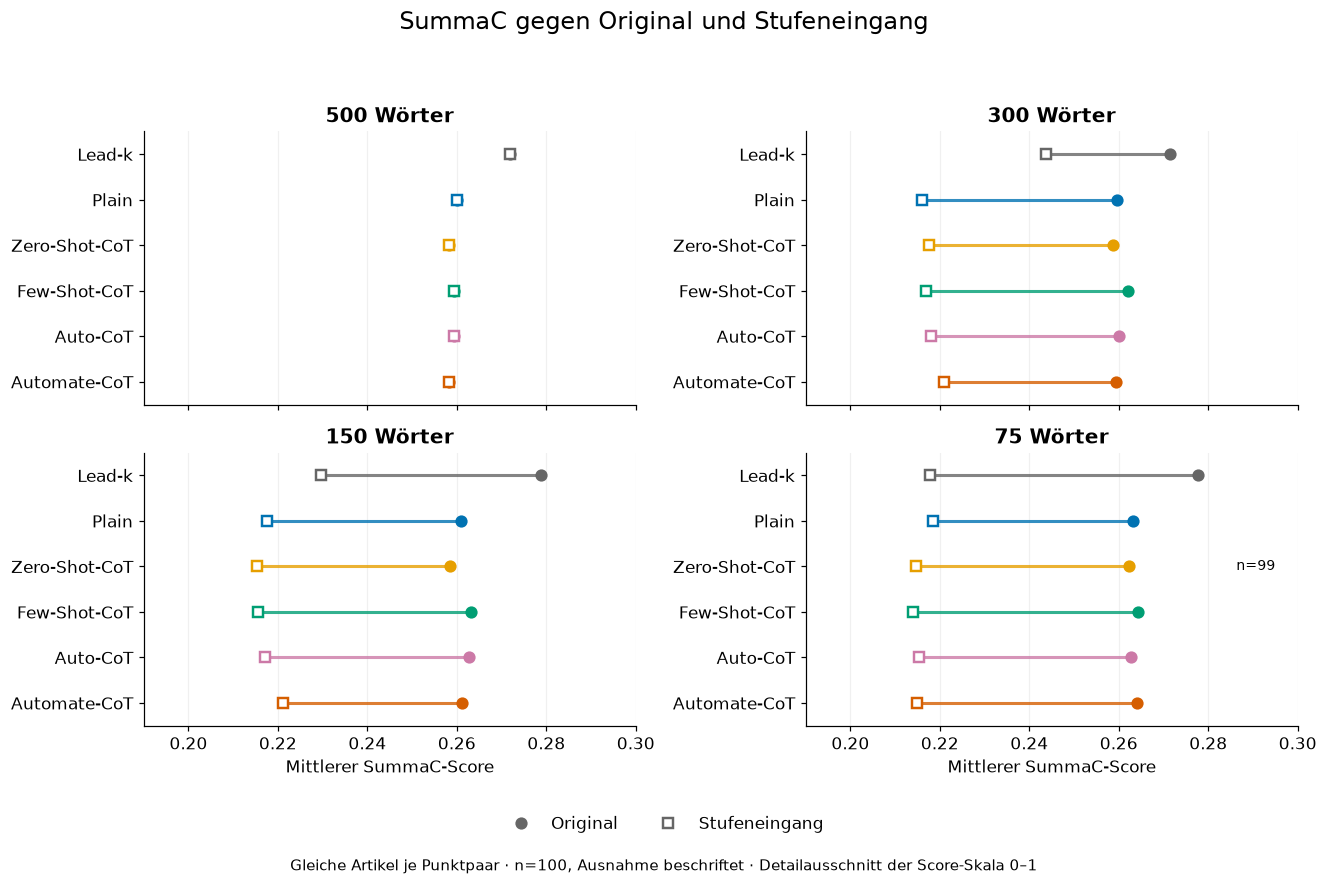

**Eigenständiger Befund:** In allen 18 Gruppen nach der ersten Stufe liegt der mittlere Score gegen den Stufeneingang niedriger als gegen das Original (Differenz -0,060 bis -0,028). Bei 500 sind beide Bezüge in allen 600 Ausgaben identisch. Die Grafik bleibt deshalb als zweite Hauptabbildung erhalten; die Richtung wird nicht als Halluzinationsnachweis interpretiert.

In [10]:
summac_rows=[]; summac_draws={}
for m in METHODS:
    for t in STAGES:
        g=analysis[analysis.method.eq(m)&analysis.stage_target_words.eq(t)].set_index("article_id").reindex(IDS)
        valid=g.source_summac.notna()&g.stage_input_summac.notna()
        diff=(g.stage_input_summac-g.source_summac).where(valid)
        stats,boot=describe(diff.to_numpy())
        summac_rows.append(dict(method=m,stage_target_words=t,original_mean_paired=g.loc[valid,"source_summac"].mean(),
                               input_mean_paired=g.loc[valid,"stage_input_summac"].mean(),**stats))
        summac_draws[f"{m}__{t}"]=boot
summac_comparison=pd.DataFrame(summac_rows)
assert summac_comparison[summac_comparison.stage_target_words.eq(500)][["mean","ci_low","ci_high"]].eq(0).all().all()
export(summac_comparison,"summac_referenzwechsel_gepaart_24_gruppen")
export(summac_comparison.assign(method_name=summac_comparison.method.map(NAMES)),"abbildung_4_5_2_punktwerte")
pass  # Große Bootstrap-Zwischendatei wird nicht benötigt.
fig,axes=plt.subplots(2,2,figsize=(12.2,8.1),sharex=True,sharey=True)
for ax,t in zip(axes.flat,STAGES):
    g=summac_comparison[summac_comparison.stage_target_words.eq(t)].set_index("method").reindex(METHODS)
    for i,(m,r) in enumerate(g.iterrows()):
        ax.plot([r.original_mean_paired,r.input_mean_paired],[i,i],color=COLORS[m],lw=2,alpha=.8)
        ax.plot(r.original_mean_paired,i,"o",color=COLORS[m],ms=7,label="Original" if i==0 else None)
        ax.plot(r.input_mean_paired,i,"s",color=COLORS[m],ms=6,markerfacecolor="white",markeredgewidth=1.6,label="Stufeneingang" if i==0 else None)
        if r.n_valid!=100: ax.text(.295,i,f"n={int(r.n_valid)}",ha="right",va="center",fontsize=9)
    ax.set_yticks(range(6),[NAMES[m] for m in METHODS]); ax.tick_params(labelleft=True)
    ax.set_ylim(5.5,-.5); ax.set_xlim(.19,.30); ax.set_xticks([.20,.22,.24,.26,.28,.30])
    ax.set_title(f"{t} Wörter",fontweight="bold"); ax.grid(axis="x",alpha=.18)
for ax in axes[1]: ax.set_xlabel("Mittlerer SummaC-Score")
handles,labels=axes.flat[0].get_legend_handles_labels()
fig.legend(handles,labels,loc="lower center",ncol=2,bbox_to_anchor=(.5,.04),frameon=False)
fig.suptitle("SummaC gegen Original und Stufeneingang",fontsize=16,y=.98)
fig.text(.5,.015,"Gleiche Artikel je Punktpaar · n=100, Ausnahme beschriftet · Detailausschnitt der Score-Skala 0–1",ha="center",fontsize=10)
fig.tight_layout(rect=[0,.10,1,.94])
savefig(fig,"abbildung_4_5_2_summac_referenzwechsel")
local_gaps=summac_comparison[summac_comparison.stage_target_words.ne(500)]
display(Markdown(f"**Eigenständiger Befund:** In allen {len(local_gaps)} Gruppen nach der ersten Stufe liegt der mittlere Score gegen den Stufeneingang niedriger als gegen das Original (Differenz {fmt(local_gaps['mean'].min(),3)} bis {fmt(local_gaps['mean'].max(),3)}). Bei 500 sind beide Bezüge in allen 600 Ausgaben identisch. Die Grafik bleibt deshalb als zweite Hauptabbildung erhalten; die Richtung wird nicht als Halluzinationsnachweis interpretiert."))


## 7. Gemeinsame Sensitivität: 98 Artikel

Die beiden Artikel mit leeren Zero-Shot-CoT-Ausgaben werden für **alle** Verfahren
und Stufen ausgeschlossen (40 und 91). Damit entfällt auch der leere Stufeneingang.
Es werden Gruppenwerte, Methodenränge, artikelweises Kendall-τ-b und alle gepaarten
Metrikvergleiche mit 10.000 Ziehungen und Seed 32 wiederholt. Ausgeschlossene Artikel
werden nicht durch Nullwerte ersetzt.

In [11]:
failed_ids=sorted(analysis.loc[analysis.empty_output.eq(1),"article_id"].unique().tolist())
assert failed_ids==[40,91]
IDS98=[a for a in IDS if a not in failed_ids]
sensitivity=analysis[analysis.article_id.isin(IDS98)].copy()
rng98=np.random.default_rng(SEED)
indices98=rng98.integers(0,len(IDS98),size=(B,len(IDS98)))
weights98=np.zeros((B,len(IDS98)),dtype=np.int16)
np.add.at(weights98,(np.repeat(np.arange(B),len(IDS98)),indices98.ravel()),1)
sens_group_rows=[]
for m in METHODS:
    for t in STAGES:
        g=sensitivity[sensitivity.method.eq(m)&sensitivity.stage_target_words.eq(t)].set_index("article_id").reindex(IDS98)
        for metric in METRICS:
            stats,_=describe(g[metric].to_numpy(),IDS98,weights98)
            sens_group_rows.append(dict(method=m,stage_target_words=t,metric=metric,**stats))
sens_groups=pd.DataFrame(sens_group_rows)
export(sens_groups,"sensitivitaet_98_gruppenmittel_95ci")
sens_groups["rank"]=sens_groups.groupby(["stage_target_words","metric"])["mean"].rank(ascending=False,method="average")
export(sens_groups,"sensitivitaet_98_methodenraenge")
sens_tau_articles=article_correlations(sensitivity,IDS98)
export(sens_tau_articles,"sensitivitaet_98_kendall_artikelebene")
sens_tau_rows=[]
for t in STAGES:
    for metric in SECONDARY:
        g=sens_tau_articles[sens_tau_articles.stage_target_words.eq(t)&sens_tau_articles.metric.eq(metric)].set_index("article_id").reindex(IDS98)
        stats,_=describe(g.tau_b.to_numpy(),IDS98,weights98)
        sens_tau_rows.append(dict(stage_target_words=t,metric=metric,**stats))
sens_tau=pd.DataFrame(sens_tau_rows)
export(sens_tau,"sensitivitaet_98_kendall_95ci")
sens_contrasts,_=paired_contrasts(sensitivity,IDS98,weights98)
export(sens_contrasts,"sensitivitaet_98_alle_gepaarten_vergleiche")
sens_summac_rows=[]
for m in METHODS:
    for t in STAGES:
        g=sensitivity[sensitivity.method.eq(m)&sensitivity.stage_target_words.eq(t)].set_index("article_id").reindex(IDS98)
        stats,_=describe((g.stage_input_summac-g.source_summac).to_numpy(),IDS98,weights98)
        sens_summac_rows.append(dict(method=m,stage_target_words=t,**stats))
sens_summac=pd.DataFrame(sens_summac_rows)
export(sens_summac,"sensitivitaet_98_summac_referenzwechsel_95ci")
assert sens_summac[sens_summac.stage_target_words.ne(500)]["mean"].lt(0).all()

robust_tau=tau_summary.merge(sens_tau,on=["stage_target_words","metric"],suffixes=("_100","_98"),validate="one_to_one")
robust_tau["same_sign"]=np.sign(robust_tau.mean_100)==np.sign(robust_tau.mean_98)
export(robust_tau,"robustheit_kendall_100_98")
robust_examples=[]
for r in selected.itertuples(index=False):
    g=sensitivity[sensitivity.stage_target_words.eq(r.stage_target_words)].pivot(index="article_id",columns="method",values=["R_obs",r.metric])
    qs,_=describe((g["R_obs"][r.method_a]-g["R_obs"][r.method_b]).reindex(IDS98).to_numpy(),IDS98,weights98)
    ss,_=describe((g[r.metric][r.method_a]-g[r.metric][r.method_b]).reindex(IDS98).to_numpy(),IDS98,weights98)
    robust_examples.append(dict(method_a=r.method_a,method_b=r.method_b,stage_target_words=r.stage_target_words,metric=r.metric,
                               n_pairs=qs["n_valid"],qa_diff=qs["mean"],qa_ci_low=qs["ci_low"],qa_ci_high=qs["ci_high"],
                               metric_diff=ss["mean"],metric_ci_low=ss["ci_low"],metric_ci_high=ss["ci_high"],
                               sign_disagreement=qs["mean"]*ss["mean"]<0))
robust_examples=pd.DataFrame(robust_examples)
export(robust_examples,"robustheit_ausgewaehlte_beispiele_98")
display(Markdown(f"Die Vorzeichen der mittleren Rangübereinstimmung bleiben in **{int(robust_tau.same_sign.sum())}/16** Zellen gleich. Die ausgewählten Widersprüche bleiben in **{int(robust_examples.sign_disagreement.sum())}/{len(robust_examples)}** Fällen erhalten. Gültiges n=98 für alle gepaarten Metrikvergleiche dieser Sensitivität."))


Die Vorzeichen der mittleren Rangübereinstimmung bleiben in **16/16** Zellen gleich. Die ausgewählten Widersprüche bleiben in **2/2** Fällen erhalten. Gültiges n=98 für alle gepaarten Metrikvergleiche dieser Sensitivität.

## 8. Belegprüfung und Diagnose neuer Zahlen

Die folgenden vollständig exportierten Referenzfälle erlauben die manuelle Prüfung
von Original, Highlights, Stufeneingang und Summary. Die Auswahl illustriert Grenzen
der Textvergleiche; sie ist keine repräsentative Stichprobe. Lesbare Textbelege stehen
in aufklappbaren Feldern, die exakten Schlüssel und Scores im CSV.

In [12]:
audit_keys=[(1,"auto_cot",500),(2,"auto_cot",500),(17,"few_shot_cot",75),(91,"zero_shot_cot",75)]
audit=pd.concat([analysis[analysis.article_id.eq(a)&analysis.method.eq(m)&analysis.stage_target_words.eq(t)] for a,m,t in audit_keys],ignore_index=True)
audit["manual_check_note"]=[
 "2006 ist im Original nicht als Ziffernfolge enthalten, aber aus 1994 + Twelve years ableitbar. 2015 für die Sanktionen wird im Originalbeleg nicht ausdrücklich genannt; der Trefferpool vermischt verschiedene Fälle.",
 "2024 in April 2024 (per the input) ist im Originalbeleg nicht angegeben; der Originaltext nennt April 1. 7 entspricht dagegen seven years old im Original. Derselbe Indikator erfasst somit eine unbelegte Jahreszuordnung und eine erhaltene Zahl in neuer Schreibweise.",
 "Keine neuen normalisierten Ziffernfolgen gegenüber Original; der Indikator prüft weder die Zuordnung vorhandener Zahlen noch alle inhaltlichen Aussagen.",
 "Unmittelbarer 150-Wörter-Eingang ist leer, 75-Wörter-Ausgabe nicht leer. Gespeicherter lokaler SummaC-Wert darf nicht als Konsistenz gegenüber einer vorhandenen Vorstufe interpretiert werden."
]
export(audit,"belegpruefung_referenzen_zahlen_4_faelle")
for r in audit.itertuples(index=False):
    heading=f"Artikel {r.article_id} · {NAMES[r.method]} · {r.stage_target_words} Wörter"
    details="".join(f"<h4>{title}</h4><pre style='white-space:pre-wrap;font-size:13px'>{html.escape(str(value))}</pre>" for title,value in [
        ("Original",r.article),("Menschliche Highlights",r.highlights),("Unmittelbarer Stufeneingang",r.stage_input),("Zusammenfassung",r.summary)])
    display(HTML(f"<details><summary><b>{heading}</b></summary><p>{html.escape(r.manual_check_note)}</p><p>Neue Werte vs. Original: {html.escape(r.novel_numeric_tokens_vs_article) or 'keine'}</p>{details}</details>"))
diagnostic_view=diagnostics[["method_name","stage_target_words","numeric_original_rate","numeric_local_rate","discordant_mean_article","n_qa_missing"]].copy()
for c in ["numeric_original_rate","numeric_local_rate","discordant_mean_article"]:
    diagnostic_view[c]=diagnostic_view[c].map(lambda v:fmt(100*v,1)+" %")
diagnostic_view=diagnostic_view.rename(columns={"method_name":"Verfahren","stage_target_words":"Zielwörter",
 "numeric_original_rate":"Neue Zahlen vs. Original","numeric_local_rate":"Neue Zahlen vs. Eingang",
 "discordant_mean_article":"Referenzabweichende QA (Artikelmittel)","n_qa_missing":"Technisch fehlende QA"})
display(diagnostic_view)


,Verfahren,Zielwörter,Neue Zahlen vs. Original,Neue Zahlen vs. Eingang,Referenzabweichende QA (Artikelmittel),Technisch fehlende QA
0,Auto-CoT,75,"38,0 %","16,0 %","11,7 %",2
1,Auto-CoT,150,"42,0 %","2,0 %","13,5 %",13
2,Auto-CoT,300,"46,0 %","5,0 %","12,6 %",11
3,Auto-CoT,500,"44,0 %","44,0 %","12,1 %",12
4,Automate-CoT,75,"38,0 %","12,0 %","11,2 %",5
5,Automate-CoT,150,"42,0 %","14,0 %","12,8 %",9
6,Automate-CoT,300,"42,0 %","4,0 %","12,1 %",16
7,Automate-CoT,500,"44,0 %","44,0 %","10,9 %",11
8,Few-Shot-CoT,75,"51,0 %","18,0 %","11,3 %",8
9,Few-Shot-CoT,150,"52,0 %","7,0 %","13,2 %",15


## 9. Kurze Ergebnisfassung für Kapitel 4.5

Der folgende Text wird unmittelbar aus den geprüften Ergebnissen erstellt. Er hält
Ergebnisbericht und mögliche Ursachen getrennt; die vertiefte Interpretation gehört
in Kapitel 5. Vollständige Mittelwerte, Rangfolgen und Diagnostik stehen im Anhangexport.

In [13]:
lines=["# 4.5 Weitere Evaluationsmetriken", "",
 "Die explorative Auswertung umfasst 100 Artikel, sechs Verfahren und vier Kompressionsstufen (2.400 Ausgaben). ROUGE und BERTScore vergleichen jede Ausgabe mit den menschlichen CNN/DailyMail-Highlights; SummaC wird getrennt gegen den Originalartikel und den unmittelbaren Stufeneingang ausgewertet. Die beobachtete QA-Retention bleibt retained / gültige QA-Urteile; 196 technische QA-Fehlwerte zählen nicht als Lost. Gruppenmittel gewichten Artikel gleich. Die Highlights umfassen im Median "+fmt(reference_lengths.highlight_words.median(),0)+" Wörter und repräsentieren eine andere Referenz als die 20 Ausgangsfakten.", "",
 f"Für die Methodenordnung wurde pro Artikel und Stufe Kendall-τ-b zwischen QA und jeder der vier Sekundärmetriken berechnet. Die Zahl gültiger Artikel liegt bei {int(tau_summary.n_valid.min())}–{int(tau_summary.n_valid.max())} je Zelle. {negative} der 16 mittleren Rangübereinstimmungen sind negativ (Abbildung 4.5-1). Die punktweisen 95-%-Intervalle beruhen auf 10.000 Artikelbootstrap-Ziehungen mit Seed 32; sie erfassen die Variation der Artikel, nicht die Unsicherheit der Modelle.", ""]
r150=tau_summary[tau_summary.stage_target_words.eq(150)&tau_summary.metric.eq("highlight_bertscore_f1")].iloc[0]
r500=tau_summary[tau_summary.stage_target_words.eq(500)&tau_summary.metric.eq("source_summac")].iloc[0]
lines.append(f"ROUGE-L und BERTScore zeigen auf allen vier Stufen negative mittlere Rangübereinstimmungen mit QA; sämtliche acht punktweisen Intervalle liegen unter null. Besonders deutlich ist die Gegenläufigkeit für BERTScore bei 150 Wörtern: τ-b={fmt(r150['mean'],3)} (95-%-Intervall {fmt(r150.ci_low,3)} bis {fmt(r150.ci_high,3)}). Die SummaC-Rangübereinstimmung liegt überwiegend nahe null; bei 500 Wörtern beträgt sie für beide Bezüge {fmt(r500['mean'],3)} (Intervall {fmt(r500.ci_low,3)} bis {fmt(r500.ci_high,3)}). Die vollständigen Punktwerte stehen in der exportierten 16-Zellen-Tabelle.")
lines+= ["",f"Die systematische Prüfung aller Methodenpaare ergibt {int(main_candidates.sign_disagreement.sum())} Vorzeichenwidersprüche unter 240 Paar-Metrik-Stufen-Vergleichen. Die folgenden höchstens zwei Beispiele wurden nachträglich anhand des größten QA-Abstands je Referenzmetrik ausgewählt; ihre Intervalle sind keine bestätigenden Tests."]
for r in selected.itertuples(index=False):
    lines += ["",f"Bei {r.stage_target_words} Wörtern erreicht {NAMES[r.method_a]} gegenüber {NAMES[r.method_b]} auf denselben {r.n_pairs} Artikeln {fmt(100*r.qa_diff)} Prozentpunkte mehr QA-Retention (95-%-Intervall {fmt(100*r.qa_ci_low)} bis {fmt(100*r.qa_ci_high)}). {MET_NAMES[r.metric]} ordnet die Verfahren umgekehrt: Differenz {fmt(r.metric_diff,4)} (Intervall {fmt(r.metric_ci_low,4)} bis {fmt(r.metric_ci_high,4)}). Die tatsächlichen Wortzahlen betragen im Mittel {fmt(r.actual_words_a,1)} gegenüber {fmt(r.actual_words_b,1)}; {r.over_window_a} gegenüber {r.over_window_b} Ausgaben überschreiten das Wortfenster. Dieser Vergleich ist nicht längenbereinigt."]
lines += ["",f"Die beiden SummaC-Bezüge stimmen bei 500 Wörtern für alle 600 Ausgaben exakt überein. Nach der ersten Stufe liegt der mittlere Score gegen den unmittelbaren Stufeneingang in allen 18 Gruppen niedriger als gegen das Original; die gepaarten Unterschiede liegen zwischen {fmt(local_gaps['mean'].min(),3)} und {fmt(local_gaps['mean'].max(),3)} (Abbildung 4.5-2). Das beschreibt den Einfluss des Referenztextes auf den Score, keine Anzahl verlorener Fakten und keinen gesicherten Halluzinationsbefund.", "",
 "Die zwei leeren Ausgaben tragen ausdrücklich gespeicherte Score-Nullwerte. Ein weiterer Fall mit leerem Stufeneingang wird bei lokalen Vergleichen als nicht auswertbar geführt (Zero-Shot-CoT, 75 Wörter; n=99); seine Originalbezüge bleiben auswertbar. Nach gemeinsamem Ausschluss der betroffenen Artikel 40 und 91 bleiben "+str(int(robust_tau.same_sign.sum()))+"/16 Vorzeichen der mittleren Rangübereinstimmungen und "+str(int(robust_examples.sign_disagreement.sum()))+"/"+str(len(robust_examples))+" ausgewählte Widersprüche erhalten (n=98). Auch der niedrigere lokale SummaC-Mittelwert bleibt in allen 18 Gruppen nach der ersten Stufe bestehen.", "",
 "Die Zusatzdiagnostik erfasst neu normalisierte Zahlen sowie referenzabweichende QA-Antworten getrennt. Die Belegprüfung zeigt zum Beispiel einen Zahlenhit für 2006, der sich im Original aus 1994 und Twelve years ableiten lässt. Solche Treffer dürfen deshalb nicht als Halluzinationsrate ausgegeben werden. Referenzähnlichkeit, Konsistenzsignale und QA-Abdeckung ergeben hier unterschiedliche Verfahrensordnungen; daraus folgt weder eine Validierung einer Metrik noch ein Kausalnachweis. Ursachen und Qualitätsbewertungen werden in Kapitel 5 diskutiert."]
chapter_text="\n".join(lines)
(OUT/"Kapitel_4_5_Ergebnisfassung.md").write_text(chapter_text+"\n",encoding="utf-8")
display(Markdown(chapter_text))
summary_text=f"**Kurzbefund:** {negative}/16 mittlere Artikel-Rangübereinstimmungen sind negativ; gültiges n={min_valid}–{int(tau_summary.n_valid.max())}. {int(main_candidates.sign_disagreement.sum())}/240 Methodenpaar-Vergleiche haben gegensätzliche mittlere QA- und Sekundärmetrik-Differenzen. SummaC gegen Stufeneingang liegt nach der ersten Stufe in allen 18 Gruppen unter dem Originalbezug. Die 98-Artikel-Sensitivität erhält {int(robust_tau.same_sign.sum())}/16 Vorzeichen und {int(robust_examples.sign_disagreement.sum())}/{len(robust_examples)} ausgewählte Widersprüche. **Ein leerer Stufeneingang ist in lokalen Metriken als fehlend ausgewiesen.**"
print(summary_text)


# 4.5 Weitere Evaluationsmetriken

Die explorative Auswertung umfasst 100 Artikel, sechs Verfahren und vier Kompressionsstufen (2.400 Ausgaben). ROUGE und BERTScore vergleichen jede Ausgabe mit den menschlichen CNN/DailyMail-Highlights; SummaC wird getrennt gegen den Originalartikel und den unmittelbaren Stufeneingang ausgewertet. Die beobachtete QA-Retention bleibt retained / gültige QA-Urteile; 196 technische QA-Fehlwerte zählen nicht als Lost. Gruppenmittel gewichten Artikel gleich. Die Highlights umfassen im Median 50 Wörter und repräsentieren eine andere Referenz als die 20 Ausgangsfakten.

Für die Methodenordnung wurde pro Artikel und Stufe Kendall-τ-b zwischen QA und jeder der vier Sekundärmetriken berechnet. Die Zahl gültiger Artikel liegt bei 99–100 je Zelle. 12 der 16 mittleren Rangübereinstimmungen sind negativ (Abbildung 4.5-1). Die punktweisen 95-%-Intervalle beruhen auf 10.000 Artikelbootstrap-Ziehungen mit Seed 32; sie erfassen die Variation der Artikel, nicht die Unsicherheit der Modelle.

ROUGE-L und BERTScore zeigen auf allen vier Stufen negative mittlere Rangübereinstimmungen mit QA; sämtliche acht punktweisen Intervalle liegen unter null. Besonders deutlich ist die Gegenläufigkeit für BERTScore bei 150 Wörtern: τ-b=-0,544 (95-%-Intervall -0,593 bis -0,494). Die SummaC-Rangübereinstimmung liegt überwiegend nahe null; bei 500 Wörtern beträgt sie für beide Bezüge 0,067 (Intervall -0,004 bis 0,139). Die vollständigen Punktwerte stehen in der exportierten 16-Zellen-Tabelle.

Die systematische Prüfung aller Methodenpaare ergibt 166 Vorzeichenwidersprüche unter 240 Paar-Metrik-Stufen-Vergleichen. Die folgenden höchstens zwei Beispiele wurden nachträglich anhand des größten QA-Abstands je Referenzmetrik ausgewählt; ihre Intervalle sind keine bestätigenden Tests.

Bei 150 Wörtern erreicht Auto-CoT gegenüber Lead-k auf denselben 100 Artikeln 27,76 Prozentpunkte mehr QA-Retention (95-%-Intervall 24,84 bis 30,74). ROUGE-L F1 ordnet die Verfahren umgekehrt: Differenz -0,0658 (Intervall -0,0811 bis -0,0510). Die tatsächlichen Wortzahlen betragen im Mittel 215,4 gegenüber 150,0; 97 gegenüber 0 Ausgaben überschreiten das Wortfenster. Dieser Vergleich ist nicht längenbereinigt.

Bei 150 Wörtern erreicht Automate-CoT gegenüber Lead-k auf denselben 100 Artikeln 23,71 Prozentpunkte mehr QA-Retention (95-%-Intervall 20,64 bis 26,77). BERTScore F1 ordnet die Verfahren umgekehrt: Differenz -0,0240 (Intervall -0,0262 bis -0,0217). Die tatsächlichen Wortzahlen betragen im Mittel 200,1 gegenüber 150,0; 88 gegenüber 0 Ausgaben überschreiten das Wortfenster. Dieser Vergleich ist nicht längenbereinigt.

Die beiden SummaC-Bezüge stimmen bei 500 Wörtern für alle 600 Ausgaben exakt überein. Nach der ersten Stufe liegt der mittlere Score gegen den unmittelbaren Stufeneingang in allen 18 Gruppen niedriger als gegen das Original; die gepaarten Unterschiede liegen zwischen -0,060 und -0,028 (Abbildung 4.5-2). Das beschreibt den Einfluss des Referenztextes auf den Score, keine Anzahl verlorener Fakten und keinen gesicherten Halluzinationsbefund.

Die zwei leeren Ausgaben tragen ausdrücklich gespeicherte Score-Nullwerte. Ein weiterer Fall mit leerem Stufeneingang wird bei lokalen Vergleichen als nicht auswertbar geführt (Zero-Shot-CoT, 75 Wörter; n=99); seine Originalbezüge bleiben auswertbar. Nach gemeinsamem Ausschluss der betroffenen Artikel 40 und 91 bleiben 16/16 Vorzeichen der mittleren Rangübereinstimmungen und 2/2 ausgewählte Widersprüche erhalten (n=98). Auch der niedrigere lokale SummaC-Mittelwert bleibt in allen 18 Gruppen nach der ersten Stufe bestehen.

Die Zusatzdiagnostik erfasst neu normalisierte Zahlen sowie referenzabweichende QA-Antworten getrennt. Die Belegprüfung zeigt zum Beispiel einen Zahlenhit für 2006, der sich im Original aus 1994 und Twelve years ableiten lässt. Solche Treffer dürfen deshalb nicht als Halluzinationsrate ausgegeben werden. Referenzähnlichkeit, Konsistenzsignale und QA-Abdeckung ergeben hier unterschiedliche Verfahrensordnungen; daraus folgt weder eine Validierung einer Metrik noch ein Kausalnachweis. Ursachen und Qualitätsbewertungen werden in Kapitel 5 diskutiert.

**Kurzbefund:** 12/16 mittlere Artikel-Rangübereinstimmungen sind negativ; gültiges n=99–100. 166/240 Methodenpaar-Vergleiche haben gegensätzliche mittlere QA- und Sekundärmetrik-Differenzen. SummaC gegen Stufeneingang liegt nach der ersten Stufe in allen 18 Gruppen unter dem Originalbezug. Die 98-Artikel-Sensitivität erhält 16/16 Vorzeichen und 2/2 ausgewählte Widersprüche. **Ein leerer Stufeneingang ist in lokalen Metriken als fehlend ausgewiesen.**


## 10. Anhang und Exportstatus

Die CSV-Dateien enthalten ungerundete Punktwerte, Nenner und Intervalle. NPZ-Dateien
enthalten die 10.000 Bootstrap-Ergebnisse für Gruppenmittel, Rangübereinstimmung,
gepaarte Methodenvergleiche und SummaC-Referenzwechsel. Die Abbildungen werden als
PNG, SVG und PDF gespeichert. Versions- und Quellenmanifest dokumentieren alle
Join-Schlüssel, Regeln und Ausnahmen. Zur Nachberechnung das Notebook von oben
nach unten im Ordner mit den mitgelieferten Daten ausführen.

In [14]:
execution_manifest=dict(version=VERSION,join_keys=KEY,n_articles=len(IDS),n_rows=len(analysis),n_methods=len(METHODS),stages=STAGES,
 seed=SEED,bootstrap_samples=B,bootstrap_unit="article",interval="pointwise percentile 95%; no multiplicity correction",
 estimand="equal-weight article mean; QA retained/valid judgments per article",source_manifest_sha256=sha(DATA/"source_manifest.json"),
 metric_source_manifest_sha256=sha(METDATA/"source_manifest.json"),source_hashes=source_hashes,software=software,python=platform.python_version(),
 metrics=MET_NAMES,score_recomputation="ROUGE and numeric indicators all rows; frozen BERTScore/SummaC; no model reexecution",
 n_qa_technical_missing=int(analysis.n_missing.sum()),empty_output_zero_rule_rows=analysis.loc[analysis.empty_output.eq(1),KEY].to_dict("records"),
 empty_input_local_metrics_missing_rows=analysis.loc[analysis.empty_input,KEY].to_dict("records"),
 kendall_policy="all six methods required; ties handled by tau-b; missing and constant panels undefined",
 kendall_plot_rule="minimum 80 valid articles in each cell",kendall_plot_used=bool(use_tau),
 selection_rule="largest absolute paired QA gap among sign disagreements with two pointwise intervals excluding zero; ROUGE-L then BERTScore; distinct pair-stage; exploratory",
 sensitivity_excluded_ids=failed_ids,checks=dict(unique_2400_keys=True,summary_and_input_hashes_match_42_43=True,
 chapter_44_source_hashes_match=True,rouge_all_7200_scores_match=True,numeric_all_4800_indicators_match=True,
 archived_384_group_means_match=True,summac_500_equal_all_600=True),
 semantic_score_binding_limit=metric_manifest["score_binding"])
(OUT/"execution_manifest.json").write_text(json.dumps(execution_manifest,ensure_ascii=False,indent=2)+"\n")
result_files=sorted(p.name for p in OUT.iterdir() if p.is_file())
# Das Inventar enthält auch diesen ausdrücklich wiederverwendeten historischen Eingang.
rouge_cache = DATA_DIR / "caches/06_weitere_metriken/rouge_nachberechnung_2400.csv"
inventory_files = [p for p in OUT.iterdir() if p.is_file() and p.name != "export_manifest.csv"] + [rouge_cache]
export(pd.DataFrame([dict(file=p.name,sha256=sha(p),bytes=p.stat().st_size) for p in inventory_files]),"export_manifest")
print(f"Exportiert: {len(result_files)} Ergebnisdateien; sechs Grafikdateien (PNG, SVG und PDF). Ordner: {OUT.name}")


Exportiert: 32 Ergebnisdateien; sechs Grafikdateien (PNG, SVG und PDF). Ordner: 06_weitere_metriken
